In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_pickle("dane.pkl")
df.shape

(421570, 17)

Łączenie sprzedaży w czasie

In [26]:
tydzien = df.groupby("Date")["Weekly_Sales"].sum()
tydzien.head()

Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Name: Weekly_Sales, dtype: float64

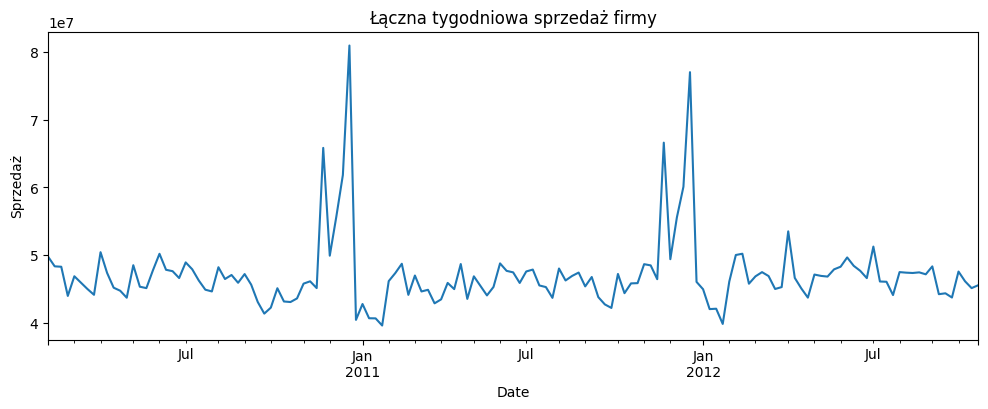

In [27]:
import matplotlib.pyplot as plt

tydzien.plot(figsize=(12, 4), title="Łączna tygodniowa sprzedaż firmy")
plt.ylabel("Sprzedaż")
plt.show()

Sprzedaż, w których tygodniach była największa

In [28]:
top = tydzien.sort_values(ascending=False).head()

tygodnie = pd.DataFrame({
    "początek tyg": top.index - pd.Timedelta(days=6),
    "koniec tyg": top.index,
    "wielkość sprzedaży": top.values
})
print(tygodnie)

  początek tyg koniec tyg  wielkość sprzedaży
0   2010-12-18 2010-12-24         80931415.60
1   2011-12-17 2011-12-23         76998241.31
2   2011-11-19 2011-11-25         66593605.26
3   2010-11-20 2010-11-26         65821003.24
4   2010-12-11 2010-12-17         61820799.85


Top 10 sklepów z najlepszą sprzedażą

In [25]:
sklep = df.groupby(["Store","Type"])["Weekly_Sales"].sum()
sklep = sklep.sort_values(ascending=False)
sklep.head(10)

sklep_mln = (sklep / 1_000_000).round(1).rename("Sales_mln").reset_index()
print(sklep_mln.head(10))

   Store Type  Sales_mln
0     20    A      301.4
1      4    A      299.5
2     14    A      289.0
3     13    A      286.5
4      2    A      275.4
5     10    B      271.6
6     27    A      253.9
7      6    A      223.8
8      1    A      222.4
9     39    A      207.4


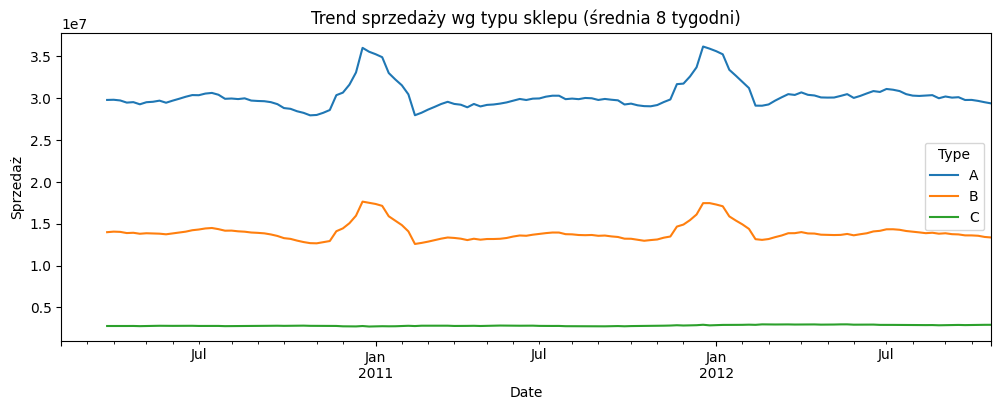

In [24]:
typy = df.groupby(["Date", "Type"])["Weekly_Sales"].sum().unstack()
typy_srednia = typy.rolling(window=8).mean()

typy_srednia.plot(figsize=(12, 4), title="Trend sprzedaży wg typu sklepu (średnia 8 tygodni)")
plt.ylabel("Sprzedaż")
plt.show()

Działy z najlepszą sprzedażą

In [35]:
dzial = df.groupby("Dept")["Weekly_Sales"].sum()
dzial = dzial.sort_values(ascending=False)

dzial_mln = (dzial / 1_000_000).round(1).rename("sales_mln").reset_index()
dzial_mln.head(10)


,Dept,sales_mln
0,92,483.9
1,95,449.3
2,38,393.1
3,72,305.7
4,90,291.1
5,40,288.9
6,2,280.6
7,91,216.8
8,13,197.3
9,8,194.3


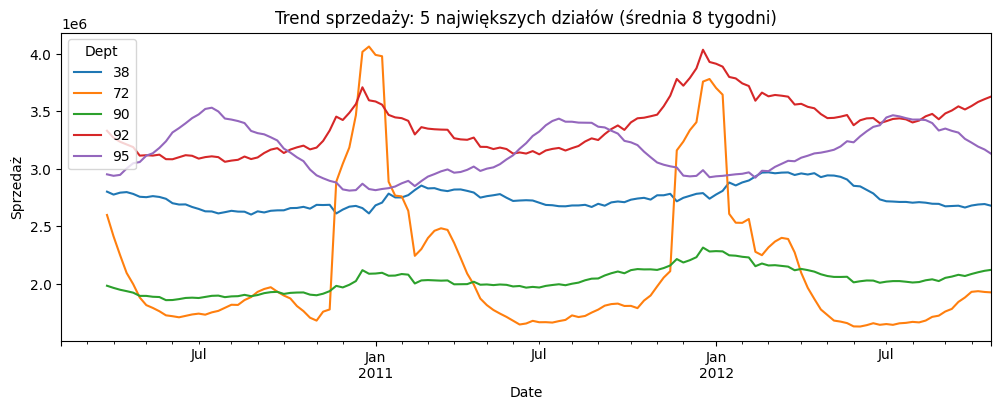

In [37]:
top5_dzial = dzial.head(5).index

dzial_tyg = (
    df[df["Dept"].isin(top5_dzial)]
    .groupby(["Date", "Dept"])["Weekly_Sales"]
    .sum()
    .unstack()
)

dzial_tyg.rolling(window=8).mean().plot(
    figsize=(12, 4),
    title="Trend sprzedaży: 5 największych działów (średnia 8 tygodni)"
)
plt.ylabel("Sprzedaż")
plt.show()

In [ ]:
print("")